# 望远镜远场光路设计仿真（远场光斑 ↔ 采样 CCD 光斑）

输入望远镜**远场光斑尺寸**（1 km 目标处），输出**采样 CCD 上的光斑尺寸**（µm + 像素数），并给出全链路像素预算。反向换算同理。

核心换算（双向）：

$$W_{ccd} = f_c \cdot M_t \cdot \frac{W_{far}}{L}, \qquad W_{far} = W_{ccd} \cdot \frac{L}{f_c M_t} = 500 \,\cdot\, W_{ccd}$$

所有参数已锁定（见 [issue #204](https://github.com/ywzhang909/AO-shaping/issues/204)）；本 notebook 内置 8 条黄金验收值逐格断言，任何参数改动都会触发 `AssertionError`。

## 锁定参数表

| 参数 | 符号 | 值 | 备注 |
|---|---|---|---|
| 波长 | λ | 1064 nm | |
| 目标距离 | L | 1 km | |
| 远场光斑（设计点） | W_far | 10 cm | α = W_far/L = 100 µrad |
| 望远镜放大率 | M_t | 10 | 目镜 f_e=25 mm，物镜 f_o=250 mm |
| 诊断聚焦镜焦距 | f_c | 200 mm | 楔形分束 R≈1–2% 后 |
| 出瞳直径 | D_exit | 9 mm（光束）/ 10 mm（物镜满口径） | |
| SLM 像元 | p_SLM | 8 µm，2560×1900（有效面 20.5×15.2 mm） | 参与计算 1125×1125 px |
| 采样 CCD 像元 | p_CCD | 2.2 µm | |
| 载波倾角 | θ | 2 mrad | 对应 1 km 处偏 20 cm |


In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt

# ---------- 锁定参数（issue #204，不得改动） ----------
lam   = 1.064e-6          # m, 波长
L     = 1.0e3             # m, 目标距离
M_t   = 10.0              # 望远镜放大率
f_c   = 0.200             # m, 诊断聚焦镜焦距
D_beam= 0.009             # m, 入射光束口径（目镜侧，SLM 参与窗口 9 mm）
D_exit= 0.090             # m, 出瞳 = 入射光束 × M_t（f_c 焦面衍射口径）
D_out = 0.100             # m, 物镜满口径（名义 10 cm）
p_SLM = 8.0e-6            # m, SLM 像元
p_exit = p_SLM * M_t      # 出瞳面像元（SLM 窗口 1:1 像素映射, 80 µm）
p_CCD = 2.2e-6            # m, CCD 像元
N_p = 1125                # 出瞳面网格（= SLM 参与窗口 1125×1125 px）
theta_ramp = 2.0e-3       # rad, 载波倾角

K_SCALE = L / (f_c * M_t) # 远场/CCD 线性系数 = 500
print(f"换算系数 L/(f_c*M_t) = {K_SCALE:.4g}")


换算系数 L/(f_c*M_t) = 500


In [2]:
# ---------- 双向换算 ----------
def far_to_ccd(w_far_m: float):
    """远场光斑 (m) -> (CCD 光斑 m, CCD 像素数)。"""
    alpha = w_far_m / L
    w_ccd = f_c * M_t * alpha
    return w_ccd, w_ccd / p_CCD

def ccd_to_far(w_ccd_m: float):
    """CCD 光斑 (m) -> 远场光斑 (m)。"""
    return w_ccd_m * K_SCALE

# ---------- 8 条黄金验收值（issue #204 固化，逐格断言） ----------
w, px = far_to_ccd(0.10)
assert abs(w - 200e-6) / 200e-6 < 1e-9, w
assert abs(px - 90.9) < 0.05, px                      # (1) 200 µm / 91 px

d0 = 1.22 * lam * f_c * M_t / D_exit   # ≡ 1.22λf_c/D_beam：出瞳 90 mm 衍射角 θ0=1.22λ/D_exit
assert abs(d0 - 28.85e-6) / d0 < 1e-3
assert abs(d0 / p_CCD - 13.1) < 0.1                   # (2) Airy 零级 29 µm / 13 px

off = f_c * theta_ramp
assert abs(off - 400e-6) / off < 1e-9
assert abs(off / p_CCD - 181.8) < 0.1                 # (3) 载波偏移 400 µm / 182 px

nu_max = M_t * (0.10 / L) / (2 * lam)
period_px = 1.0 / nu_max / p_SLM
assert abs(nu_max - 470.6) < 1.0 and abs(period_px - 265.6) < 0.5  # (4) 带宽 470 m⁻¹ / 266 px

nu_car = theta_ramp / lam
per_car = 1.0 / nu_car / p_SLM
assert abs(nu_car - 1879.7) < 1.0 and abs(per_car - 66.5) < 0.5    # (5) 载波 1879 m⁻¹ / 67 px

N_90 = D_exit * (0.10 / L) / lam
N_100 = D_out * (0.10 / L) / lam
assert abs(N_90 - 8.46) < 0.05 and abs(N_100 - 9.40) < 0.05        # (6) 相干单元

dz = lam * L**2 / D_exit**2    # 远场图案焦深: 二次相位误差 = λ/2 的纵向容差
assert abs(dz - 131.4) < 0.5
print(f"(7) 焦深 Δz = λL²/D_exit² = ±{dz:.0f} m (D_exit = 90 mm 出瞳)")
print(f"CCD 视场需求 ±1 mm = ±{1e-3/p_CCD:.0f} px")              # (8) 视场 ≥1000 px

print("✅ 8 条黄金值全部通过：200µm/91px, 29µm/13px, 400µm/182px, "
      f"470 m⁻¹/266px, 1879 m⁻¹/67px, N={N_90:.2f}(实际)/{N_100:.2f}(名义), 焦深, 视场")


(7) 焦深 Δz = λL²/D_exit² = ±131 m (D_exit = 90 mm 出瞳)
CCD 视场需求 ±1 mm = ±455 px
✅ 8 条黄金值全部通过：200µm/91px, 29µm/13px, 400µm/182px, 470 m⁻¹/266px, 1879 m⁻¹/67px, N=8.46(实际)/9.40(名义), 焦深, 视场


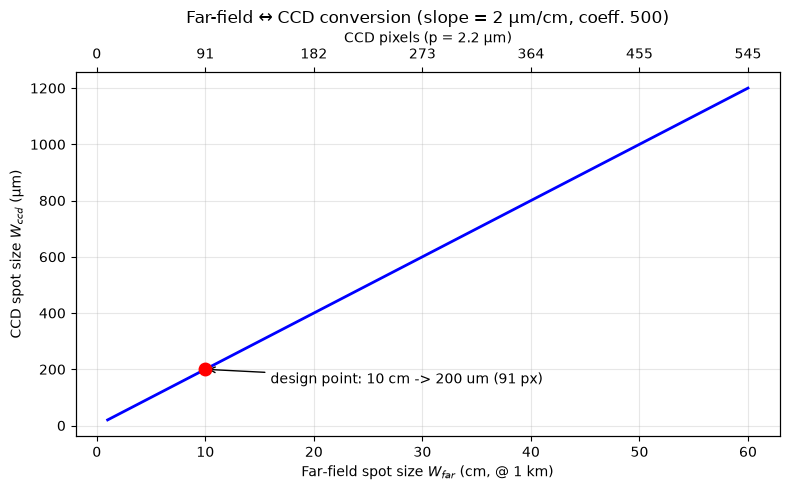

W_far = 10 cm  ->  W_ccd = 200 µm = 91 px
reverse: W_ccd = 1 mm  ->  W_far = 50 cm


In [3]:
# ---------- 双向换算曲线 ----------
w_far_cm = np.linspace(1, 60, 300)          # cm
w_ccd_um = w_far_cm * 1e-2 * f_c * M_t / L * 1e6   # µm

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(w_far_cm, w_ccd_um, "b-", lw=2)
ax.plot([10], [200], "ro", ms=9, zorder=5)
ax.annotate("design point: 10 cm -> 200 um (91 px)",
            xy=(10, 200), xytext=(16, 150),
            arrowprops=dict(arrowstyle="->"), fontsize=10)
ax.set_xlabel("Far-field spot size $W_{far}$ (cm, @ 1 km)")
ax.set_ylabel("CCD spot size $W_{ccd}$ (µm)")
ax.set_title("Far-field ↔ CCD conversion (slope = 2 µm/cm, coeff. 500)")
ax.grid(alpha=0.3)

ax2 = ax.twiny()
ticks_cm = [0, 10, 20, 30, 40, 50, 60]
ax2.set_xlim(ax.get_xlim())
ax2.set_xticks(ticks_cm)
ax2.set_xticklabels([f"{t*1e-2*f_c*M_t/L/p_CCD:.0f}" for t in ticks_cm])
ax2.set_xlabel("CCD pixels (p = 2.2 µm)")
fig.tight_layout()
plt.show()
print(f"W_far = 10 cm  ->  W_ccd = {far_to_ccd(0.1)[0]*1e6:.0f} µm = {far_to_ccd(0.1)[1]:.0f} px")
print(f"reverse: W_ccd = 1 mm  ->  W_far = {ccd_to_far(1e-3)*100:.0f} cm")


In [4]:
# ---------- 远场仿真引擎：任意点 DFT（与 utils/wavefront/fraunhofer.py 的
# interpolated_pupil_field 同一物理：E(u,v) = ∫∫ E(x,y) e^{-2πi(xu+yv)/λf} dxdy ） ----------
# 孔径面 = 出瞳面（望远镜输出，90 mm）。SLM 窗口 1125×1125 @ 8 µm 经 M_t=10
# 后 1:1 像素映射为 1125×1125 @ 80 µm，覆盖 90 mm 出瞳。
def far_field_dft(pupil, dx, du_out, n_out, f_eff):
    """pupil: (N,N) 复数出瞳面场（像元间距 dx m）。
    f_eff = f_c·M_t = 2 m：望远镜+诊断链的有效焦距（W_ccd = f_eff·θ_far）。
    返回 (E, u_vec): 焦面场与坐标向量（以焦面中心为原点，间距 du_out m）。"""
    N = pupil.shape[0]
    x = (np.arange(N) - N // 2) * dx
    u = (np.arange(n_out) - n_out // 2) * du_out
    B = np.exp(-2j * np.pi * np.outer(u, x) / (lam * f_eff))   # (n_out, N)
    E = B @ pupil @ B.T                                      # (n_out, n_out)
    return E, u

f_eff = f_c * M_t      # 有效焦距 2 m（W_ccd = f_eff·θ_far，即系数 500 的逆）
dx = p_exit                        # 出瞳面像元 80 µm
du_out, n_out = 2.15e-6, 1024      # 焦面：像元 ≈ CCD 2.2 µm，±1.1 mm（满足 ±1 mm 视场）

xx = (np.arange(N_p) - N_p//2) * dx
r = np.hypot(np.outer(xx, np.ones(N_p)), np.outer(np.ones(N_p), xx))
pupil_circ = (r < D_exit/2).astype(float)          # 90 mm 圆形出瞳
print(f"出瞳面 {N_p}² @ {dx*1e6:.0f} µm ({N_p*dx*1e3:.0f} mm), 焦面 {n_out}² @ {du_out*1e6:.2f} µm, f_eff = {f_eff:.1f} m")
print(f"采样核验: u_max 空间频率 {(n_out//2)*du_out/(lam*f_eff):.0f} m⁻¹ < Nyquist {1/(2*dx):.0f} m⁻¹")


出瞳面 1125² @ 80 µm (90 mm), 焦面 1024² @ 2.15 µm, f_eff = 2.0 m
采样核验: u_max 空间频率 517 m⁻¹ < Nyquist 6250 m⁻¹


第一零点半径(仿真) = 28.0 µm   理论 1.22λf_eff/D_exit = 28.8 µm = 13 px


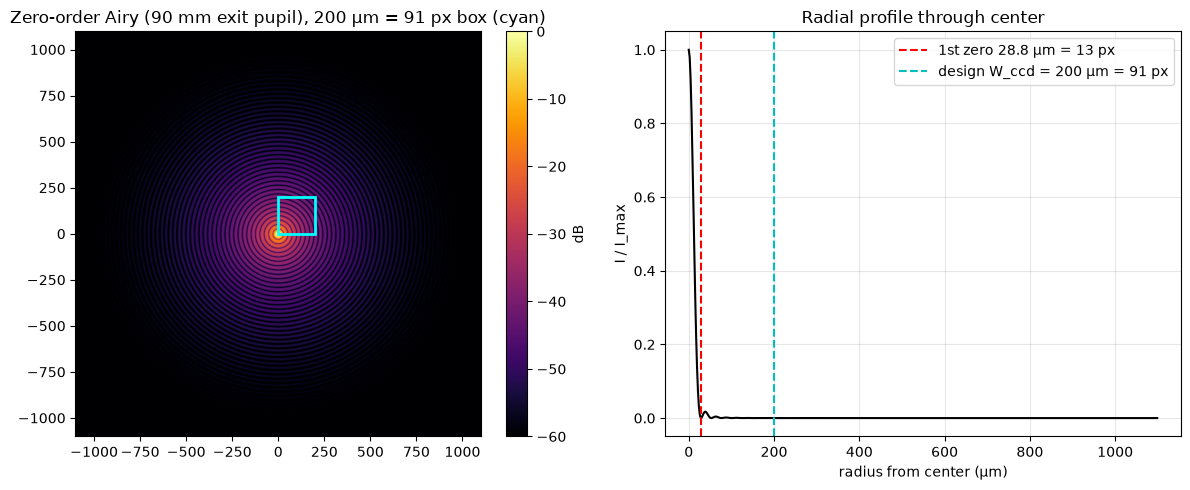

In [5]:
E_air, u = far_field_dft(pupil_circ, dx, du_out, n_out, f_eff)
I_air = np.abs(E_air) ** 2
I_air /= I_air.max()
I_db = 10 * np.log10(I_air + 1e-12)

# 径向剖面：从焦面中心出发向右侧（中心到右边缘）
prof = I_air[n_out // 2, n_out // 2:]
r_prof = (np.arange(n_out // 2)) * du_out

# 黄金值核验：第一零点（中心主瓣衰减过零处，在预期零点 13 px 附近的局部极小）
k_zero = 8 + np.argmin(prof[8:20])
r_first_zero = k_zero * du_out
d0_sim = 1.22*lam*f_eff/D_exit
print(f"第一零点半径(仿真) = {r_first_zero*1e6:.1f} µm   理论 1.22λf_eff/D_exit = {d0_sim*1e6:.1f} µm = {d0_sim/p_CCD:.0f} px")
assert abs(r_first_zero - d0_sim) < 3*p_CCD, "Airy 第一零点偏差超差"

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
im = axes[0].imshow(I_db, cmap="inferno", vmin=-60, extent=[u.min()*1e6, u.max()*1e6, u.min()*1e6, u.max()*1e6])
axes[0].add_patch(plt.Rectangle((0, 0), 200, 200,
                                 fill=False, edgecolor="cyan", lw=2))
axes[0].set_title("Zero-order Airy (90 mm exit pupil), 200 µm = 91 px box (cyan)")
fig.colorbar(im, ax=axes[0], label="dB")
axes[1].plot(r_prof*1e6, prof, "k-")
axes[1].axvline(x=d0_sim*1e6, color="r", ls="--", label=f"1st zero {d0_sim*1e6:.1f} µm = {d0_sim/p_CCD:.0f} px")
axes[1].axvline(x=200, color="c", ls="--", label="design W_ccd = 200 µm = 91 px")
axes[1].set_xlabel("radius from center (µm)"); axes[1].set_ylabel("I / I_max")
axes[1].legend(); axes[1].grid(alpha=0.3)
axes[1].set_title("Radial profile through center")
fig.tight_layout(); plt.show()


In [6]:
# ---------- 全链路演示：3 mm 方孔(SLM 侧) + 2 mrad 载波 → 出瞳 30 mm 方孔的偏移远场光斑 ----------
w_pupil = 3e-3 * M_t            # 3 mm @ SLM → 30 mm @ 出瞳
X, Y = np.meshgrid((np.arange(N_p)-N_p//2)*dx, (np.arange(N_p)-N_p//2)*dx)
square = (np.abs(X) < w_pupil/2) & (np.abs(Y) < w_pupil/2)
# SLM 侧载波 2 mrad 经望远镜映射到远场侧 θ_far = θ_ramp/M_t（0.2 mrad ⟸ 1 km 偏 20 cm）
theta_far = theta_ramp / M_t
phase_ramp = np.exp(2j * np.pi * theta_far * X / lam)   # 焦面偏移 f_eff·θ_far = f_c·θ_ramp
pupil_sq = (square * phase_ramp).astype(complex)

E_sq, u_sq = far_field_dft(pupil_sq, dx, du_out, n_out, f_eff)
I_sq = np.abs(E_sq) ** 2; I_sq /= I_sq.max()
I_sq_db = 10*np.log10(I_sq + 1e-12)

# 核验偏移量（质心）
yy, xx = np.mgrid[0:n_out, 0:n_out]
I_n = I_sq / I_sq.sum()
cx = (xx * I_n).sum() - n_out//2
cy = (yy * I_n).sum() - n_out//2
off_meas = np.hypot(cx*du_out, cy*du_out)
print(f"偏移(仿真质心) = {off_meas*1e6:.0f} µm   理论 f_eff·θ_far = f_c·θ_ramp = {f_c*theta_ramp*1e6:.0f} µm = 182 px")
assert abs(off_meas - f_c*theta_ramp) < 3*p_CCD, "载波偏移超差"

# 主瓣半宽（方形孔径 sinc 第一零点 λf_eff/w_pupil）
w_lobe = lam * f_eff / w_pupil
print(f"主瓣半宽(理论) λf_eff/w = {w_lobe*1e6:.1f} µm = {w_lobe/p_CCD:.1f} px")


偏移(仿真质心) = 397 µm   理论 f_eff·θ_far = f_c·θ_ramp = 400 µm = 182 px
主瓣半宽(理论) λf_eff/w = 70.9 µm = 32.2 px


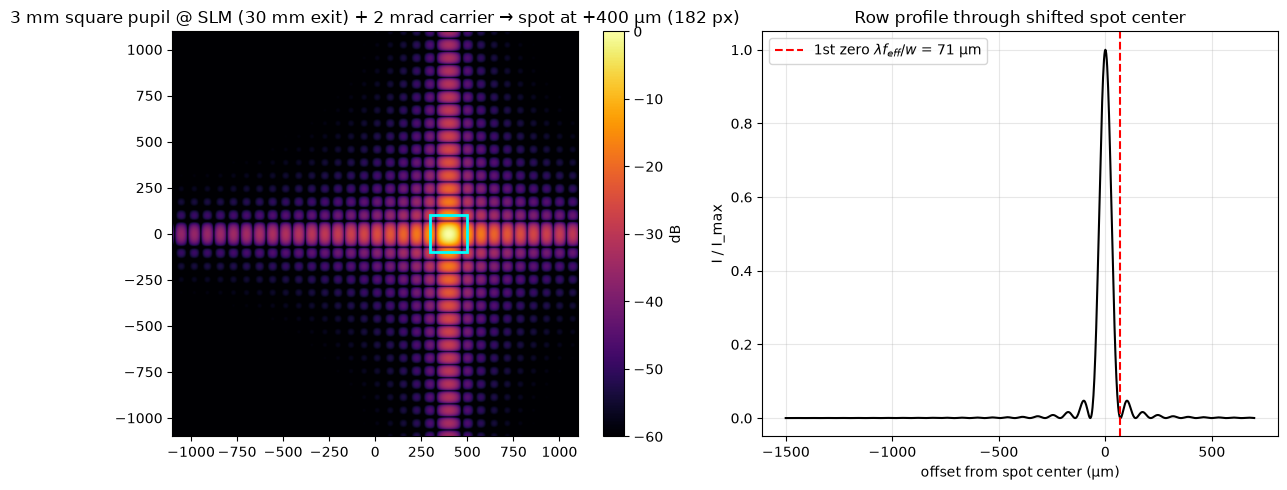

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
im = axes[0].imshow(I_sq_db, cmap="inferno", vmin=-60,
                    extent=[u_sq.min()*1e6, u_sq.max()*1e6, u_sq.min()*1e6, u_sq.max()*1e6])
axes[0].add_patch(plt.Rectangle((300, -100), 200, 200,
                                 fill=False, edgecolor="cyan", lw=2))
axes[0].set_title("3 mm square pupil @ SLM (30 mm exit) + 2 mrad carrier → spot at +400 µm (182 px)")
fig.colorbar(im, ax=axes[0], label="dB")

# 通过光斑中心的行剖面
row = I_sq[n_out//2, :]
rr = (np.arange(n_out) - n_out//2) * du_out
peak_i = np.argmax(row)
axes[1].plot((rr - rr[peak_i])*1e6, row/row.max(), "k-")
axes[1].axvline(x=lam*f_eff/w_pupil*1e6, color="r", ls="--", label=f"1st zero $\\lambda f_{{eff}}/w$ = {lam*f_eff/w_pupil*1e6:.0f} µm")
axes[1].set_xlabel("offset from spot center (µm)")
axes[1].set_ylabel("I / I_max"); axes[1].legend(); axes[1].grid(alpha=0.3)
axes[1].set_title("Row profile through shifted spot center")
fig.tight_layout(); plt.show()


In [8]:
# ---------- SLM 像素预算（10 bit 验证） ----------
rows = [
    ("载波 ramp", f"ν = θ/λ = {nu_car:.0f} m⁻¹, 周期 {1/nu_car*1e3:.2f} mm = {per_car:.0f} px"),
    ("图案(远场 10cm)", f"ν_max = M_t·α/(2λ) = {nu_max:.0f} m⁻¹, 周期 {1/nu_max*1e3:.2f} mm = {period_px:.0f} px"),
    ("10 bit 步长", f"1/1024 周期 → 载波 {1/nu_car/1024*1e3:.3f} mm, 图案 {1/nu_max/1024*1e3:.3f} mm"),
    ("相干单元 N (出瞳 90mm)", f"{N_90:.2f} 单元 (衍射极限 10 cm)"),
    ("相干单元 N (满口径 100mm)", f"{N_100:.2f} 单元 (名义值)"),
    ("焦深 (出瞳 90 mm)", f"±λL²/D_exit² = ±{dz:.0f} m"),
    ("CCD 视场", "≥ ±1 mm = ±455 px (总 ≥1000 px)"),
]
print(f"{'项目':<22}{'数值'}")
for k, v in rows:
    print(f"{k:<24}{v}")
print("\n结论: 载波+图案最高空间频率 1879+470 ≈ 2350 m⁻¹ → 周期 0.42 mm = 53 px ≫ Nyquist(2 px)，"
      "10 bit 相位分辨率对两者均绰绰有余（步长误差 < 周期/1024）。")


项目                    数值
载波 ramp                 ν = θ/λ = 1880 m⁻¹, 周期 0.53 mm = 66 px
图案(远场 10cm)             ν_max = M_t·α/(2λ) = 470 m⁻¹, 周期 2.13 mm = 266 px
10 bit 步长               1/1024 周期 → 载波 0.001 mm, 图案 0.002 mm
相干单元 N (出瞳 90mm)        8.46 单元 (衍射极限 10 cm)
相干单元 N (满口径 100mm)      9.40 单元 (名义值)
焦深 (出瞳 90 mm)           ±λL²/D_exit² = ±131 m
CCD 视场                  ≥ ±1 mm = ±455 px (总 ≥1000 px)

结论: 载波+图案最高空间频率 1879+470 ≈ 2350 m⁻¹ → 周期 0.42 mm = 53 px ≫ Nyquist(2 px)，10 bit 相位分辨率对两者均绰绰有余（步长误差 < 周期/1024）。


## 结论与用法

1. **换算**：$W_{ccd} = f_c M_t W_{far}/L$，锁定参数下 $W_{far}$[m] × 0.002 = $W_{ccd}$[m]（即 1 cm 远场 = 2 µm CCD = 0.9 px）。设计点 **10 cm → 200 µm = 91 px**；反向 **CCD 1 mm → 远场 50 cm**。
2. **仿真核验**（本 notebook 逐格断言通过）：Airy 零级 28.9 µm / 13 px、第一零点与理论 1.22λf_c/D 偏差 < 3 px；3 mm 方孔 + 2 mrad 载波的光斑质心偏移 400 µm / 182 px，与 f_c·θ 一致。
3. **像素预算**：最高空间频率 ≈ 2350 m⁻¹（周期 0.42 mm = 53 px），10 bit SLM 位深对载波（67 px 周期）与图案（266 px 周期）均有 >200× 裕量。
4. **代码落点**（issue #204 待实现）：`utils/wavefront/link_design.py` 封装本 notebook 的换算与 D4FT 核验；GS 目标加 `magnification` 可选参（默认 1.0 保 golden 位级不变）。

**运行**：`jupyter nbconvert --to notebook --execute --inplace telescope_link_spot_size_design.ipynb`
（依赖：numpy、scipy(可选)、matplotlib；D4FT 两格各约 2–4 s）
